# K-Medoids clustering of prison-system profiles

We group aggregate state-year observations and identify actual representative profiles. We use K-Medoids because no natural classification target exists in these tables. This notebook fits PAM, compares cluster counts, examines cluster characteristics and reports stability. Every chart is generated by its own plotting cell and saved for the report.

The result is exploratory: low separation and sensitivity are findings to report, not reasons to invent stronger performance. See the [methodology report](../report/k_medoids.md).

## Load the frozen numeric features

In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.mining.k_medoids import load_profiles, run_clustering
from src.preprocessing.transformation import FEATURES
sns.set_theme(style="whitegrid")
raw, scaled, x = load_profiles(ROOT)
print(f"{len(raw)} state-year profiles; {len(FEATURES)} standardized features.")
display(raw.head())
display(scaled[FEATURES].agg(["mean", "std"]))

437 state-year profiles; 5 standardized features.


,profile_id,state,year,occupancy_ratio,undertrial_share,female_share,age_18_30_share,illiterate_share
0,Andaman & Nicobar Islands|2001,Andaman & Nicobar Islands,2001,1.423792,0.433420,0.010444,0.281984,0.000000
1,Andaman & Nicobar Islands|2002,Andaman & Nicobar Islands,2002,1.230483,0.586103,0.024169,0.422961,0.000000
2,Andaman & Nicobar Islands|2003,Andaman & Nicobar Islands,2003,1.100372,0.689189,0.010135,0.611486,0.087838
3,Andaman & Nicobar Islands|2004,Andaman & Nicobar Islands,2004,0.715210,0.746606,0.013575,0.542986,0.022624
4,Andaman & Nicobar Islands|2005,Andaman & Nicobar Islands,2005,0.724919,0.705357,0.017857,0.410714,0.053571


,occupancy_ratio,undertrial_share,female_share,age_18_30_share,illiterate_share
mean,-2.926721e-16,-7.235504e-16,-1.382063e-16,-2.438934e-17,-2.926721e-16
std,1.001146e+00,1.001146e+00,1.001146e+00,1.001146e+00,1.001146e+00


Means should be near zero; pandas' displayed standard deviation uses ddof=1, whereas the frozen StandardScaler used population variance (ddof=0). IDs, state, year, raw counts and categorical transaction bins are excluded from clustering distances. All features have equal weights after z-score scaling.

## Fit PAM and compare candidate settings

Primary distance is Manhattan; Euclidean is a sensitivity check. We compare k=2 through 8, retain the lowest-objective fit of BUILD plus seeds 42–45 for each setting, and select the highest silhouette among Manhattan solutions with at least 22 profiles per cluster. This 5% size threshold is an explicit choice for broad profile groups. PAM performs actual medoid swaps, not centroid updates. Its objective is a sum of distances to real representatives.

In [2]:
summary = run_clustering(ROOT)
TABLES = ROOT / "results/tables/k_medoids"
PLOTS = ROOT / "results/plots/k_medoids"
PLOTS.mkdir(parents=True, exist_ok=True)
comparison = pd.read_csv(TABLES / "candidate_k_comparison.csv")
assignments = pd.read_csv(TABLES / "cluster_assignments.csv")
medoids = pd.read_csv(TABLES / "medoids.csv")
sizes = pd.read_csv(TABLES / "cluster_sizes.csv")
print({key: summary[key] for key in ["selected_k", "silhouette", "objective", "minimum_cluster_size"]})
display(comparison)

{'selected_k': 2, 'silhouette': 0.17447707939550836, 'objective': 1459.8623650936202, 'minimum_cluster_size': 22}


,metric,k,objective,objective_per_profile,silhouette,min_cluster_size,max_cluster_size,eligible,mean_start_ari,min_start_ari,best_swaps
0,cityblock,2,1459.862365,3.340646,0.174477,167,270,True,0.329846,0.066091,1
1,cityblock,3,1344.389986,3.076407,0.169536,90,217,True,0.434522,0.188821,1
2,cityblock,4,1264.591669,2.893802,0.145515,90,138,True,0.546579,0.193401,2
3,cityblock,5,1199.563605,2.744997,0.151350,56,137,True,0.652658,0.482143,9
4,cityblock,6,1145.280323,2.620779,0.151632,42,131,True,0.516619,0.310810,3
5,cityblock,7,1098.487651,2.513702,0.187562,18,141,False,0.919923,0.799809,3
6,cityblock,8,1059.302284,2.424033,0.181102,18,130,False,0.801957,0.639474,12
7,euclidean,2,783.104302,1.792001,0.172022,172,265,True,0.388244,0.039340,1
8,euclidean,3,735.353645,1.682731,0.171336,85,218,True,0.430657,0.184922,4
9,euclidean,4,696.375295,1.593536,0.141060,73,144,True,0.614280,0.351328,4


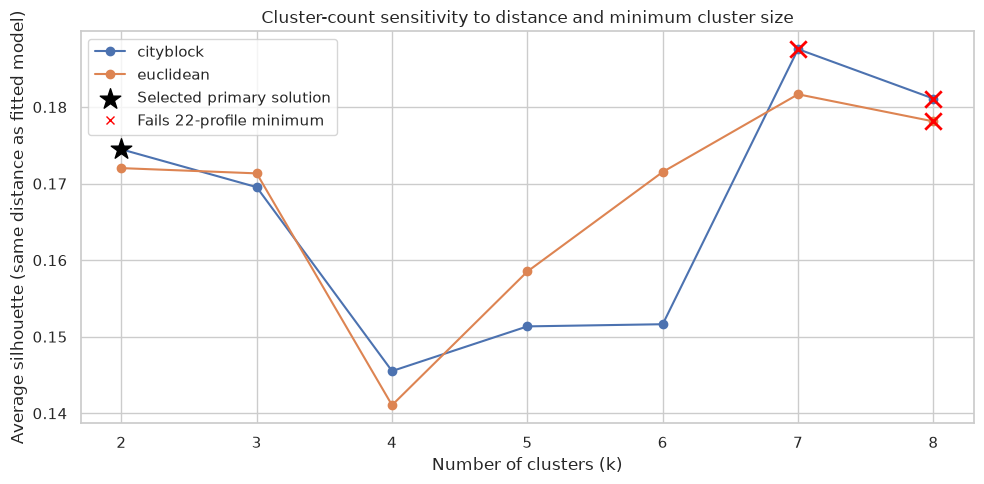

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for metric, group in comparison.groupby("metric", sort=False):
    ax.plot(group.k, group.silhouette, marker="o", label=metric)
    rejected = group[~group.eligible]
    ax.scatter(rejected.k, rejected.silhouette, marker="x", s=140, linewidths=2, color="red", zorder=4)
ax.scatter(summary["selected_k"], summary["silhouette"], marker="*", s=240, color="black", label="Selected primary solution", zorder=5)
ax.plot([], [], marker="x", color="red", linestyle="none", label="Fails 22-profile minimum")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Average silhouette (same distance as fitted model)")
ax.set_title("Cluster-count sensitivity to distance and minimum cluster size")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "cluster_count_selection.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** The declared selection rule retains k=2 (silhouette 0.1745). Unrestricted Manhattan silhouette is higher at k=7 (0.1876), but its smallest cluster contains 18 profiles and fails the declared size rule. Euclidean selects k=7 among its eligible candidates. The result depends on analyst choices, and separation is weak.

## Real medoids and profile differences

In [4]:
display(medoids)
display(sizes)
median_percentages = assignments.groupby("cluster")[FEATURES].median() * 100
median_percentages.columns = [name + " (%)" for name in FEATURES]
display(median_percentages.round(2))

,cluster,profile_id,state,year,occupancy_ratio,undertrial_share,female_share,age_18_30_share,illiterate_share
0,0,Kerala|2002,Kerala,2002,0.885475,0.666538,0.036045,0.432537,0.232074
1,1,Jharkhand|2007,Jharkhand,2007,1.670330,0.672558,0.036630,0.465656,0.362511


,cluster,profiles,states,years,mean_silhouette,negative_silhouettes,mean_distance,profile_share
0,0,270,32,13,0.157087,22,3.399973,0.617849
1,1,167,27,13,0.202593,1,3.244728,0.382151


,occupancy_ratio (%),undertrial_share (%),female_share (%),age_18_30_share (%),illiterate_share (%)
cluster,,,,,
0,90.74,64.55,3.58,44.11,22.92
1,160.38,67.33,3.68,47.35,37.22


**Cluster 0: relatively lower occupancy and illiterate share.** It contains 270 state-year profiles (61.78%), spanning 32 jurisdictions and all 13 years. The actual medoid is Kerala–2002. Cluster medians are 90.74% occupancy, 64.55% undertrial share, 3.58% female share, 44.11% age-18–30 share and 22.92% illiterate share. Average within-cluster silhouette is 0.157; 22 profiles have negative silhouettes. These are relative aggregate descriptions, not labels of people or fixed state categories.

**Cluster 1: relatively higher occupancy and illiterate share.** It contains 167 state-year profiles (38.22%), spanning 27 jurisdictions and all 13 years. The actual medoid is Jharkhand–2007. Cluster medians are 160.38% occupancy, 67.33% undertrial share, 3.68% female share, 47.35% age-18–30 share and 37.22% illiterate share. Average within-cluster silhouette is 0.203; 1 profiles have negative silhouettes. These are relative aggregate descriptions, not labels of people or fixed state categories.

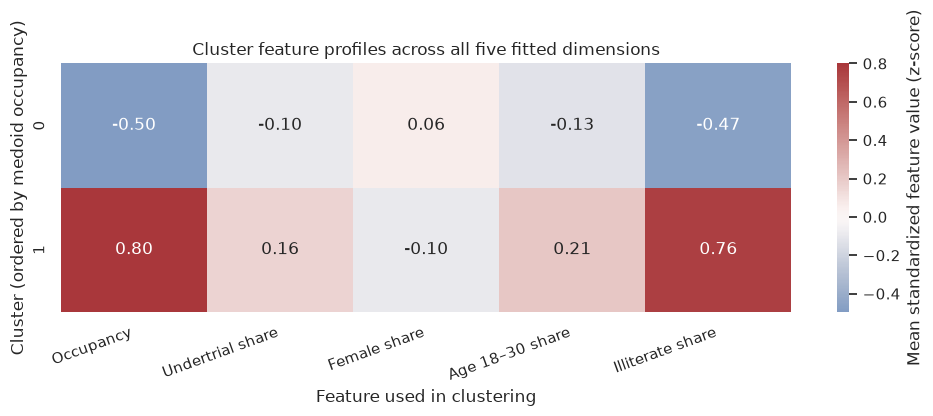

In [5]:
means = pd.read_csv(TABLES / "cluster_standardized_means.csv").set_index("cluster")
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(means, annot=True, fmt=".2f", center=0, cmap="vlag", ax=ax,
            cbar_kws={"label": "Mean standardized feature value (z-score)"})
ax.set_xlabel("Feature used in clustering")
ax.set_ylabel("Cluster (ordered by medoid occupancy)")
ax.set_title("Cluster feature profiles across all five fitted dimensions")
ax.set_xticklabels(["Occupancy", "Undertrial share", "Female share", "Age 18–30 share", "Illiterate share"], rotation=20, ha="right")
fig.tight_layout()
fig.savefig(PLOTS / "cluster_feature_profiles.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Interpretation:** Occupancy and illiterate share show the largest relative differences between the groups. Female-share medians are similar. These are descriptive aggregate contrasts, not individual risk indicators.

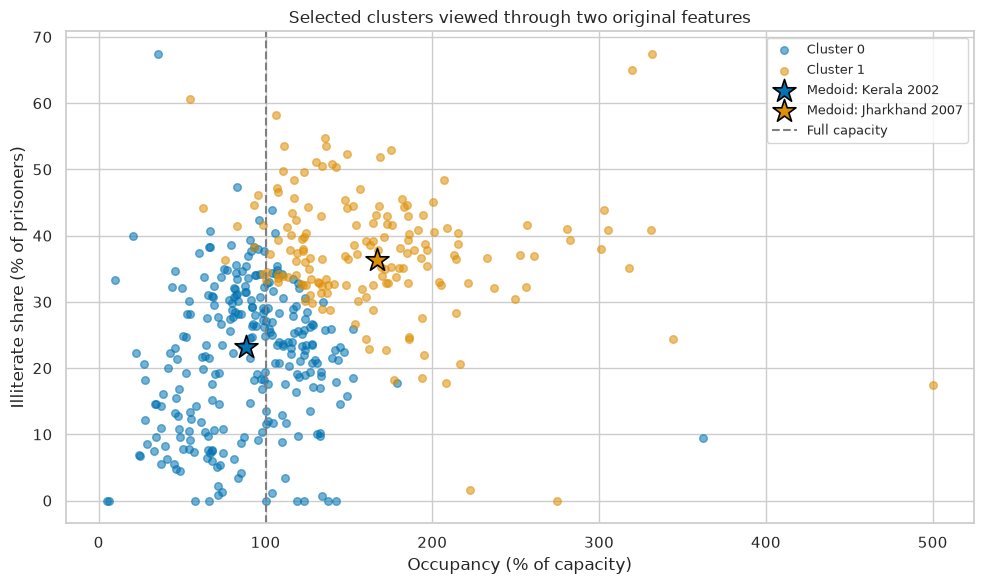

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("colorblind", n_colors=summary["selected_k"])
for cluster, group in assignments.groupby("cluster"):
    ax.scatter(group.occupancy_ratio * 100, group.illiterate_share * 100,
               alpha=.55, s=30, color=colors[cluster], label=f"Cluster {cluster}")
for row in medoids.itertuples():
    ax.scatter(row.occupancy_ratio * 100, row.illiterate_share * 100,
               marker="*", s=300, color=colors[row.cluster], edgecolor="black", linewidth=1.2,
               label=f"Medoid: {row.state} {row.year}", zorder=5)
ax.axvline(100, color="gray", linestyle="--", label="Full capacity")
ax.set_xlabel("Occupancy (% of capacity)")
ax.set_ylabel("Illiterate share (% of prisoners)")
ax.set_title("Selected clusters viewed through two original features")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(PLOTS / "occupancy_illiteracy_profiles.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

The stars are actual observations: Kerala–2002 and Jharkhand–2007. This two-feature display aids interpretation but cannot establish separation in the full five-dimensional representation. Validated extreme occupancy values remain visible.

## Evaluate separation and ambiguous assignments

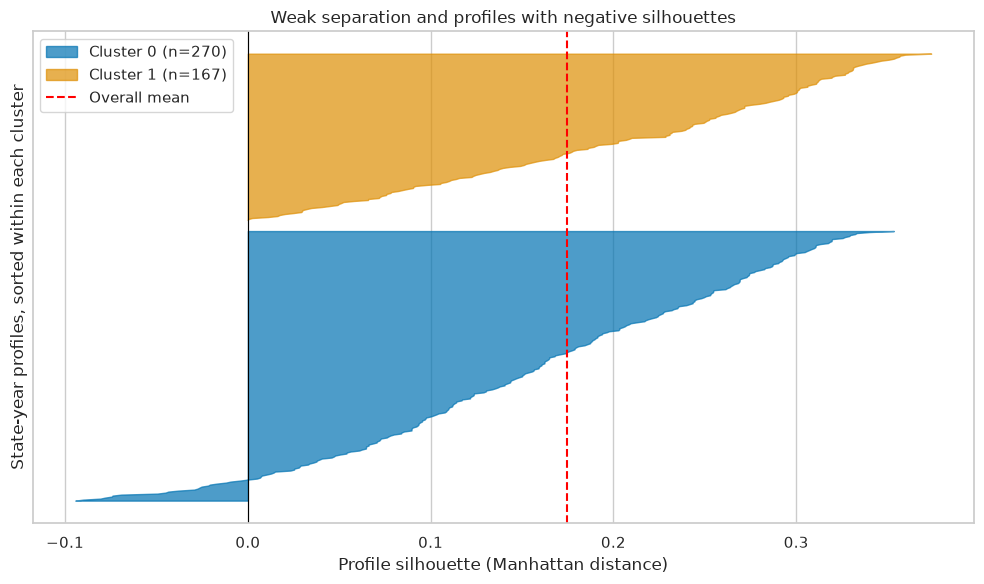

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
y_start = 10
for cluster, group in assignments.groupby("cluster"):
    values = np.sort(group.silhouette.to_numpy())
    y = np.arange(y_start, y_start + len(values))
    ax.fill_betweenx(y, 0, values, color=colors[cluster], alpha=.7, label=f"Cluster {cluster} (n={len(values)})")
    y_start += len(values) + 10
ax.axvline(summary["silhouette"], color="red", linestyle="--", label="Overall mean")
ax.axvline(0, color="black", linewidth=.8)
ax.set_xlabel("Profile silhouette (Manhattan distance)")
ax.set_ylabel("State-year profiles, sorted within each cluster")
ax.set_title("Weak separation and profiles with negative silhouettes")
ax.set_yticks([])
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "silhouette_profiles.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** Average silhouette is 0.1745; 23 profiles have negative values. Their average distance to another cluster is lower than their within-cluster average distance. Nearest-medoid assignment and average-distance silhouette use different criteria, so this does not imply an assignment bug.

## Check initialization and geographic-composition stability

In [8]:
starts = pd.read_csv(TABLES / "initialization_runs.csv")
stability = pd.read_csv(TABLES / "state_block_stability.csv")
display(starts[(starts.metric == "cityblock") & (starts.k == summary["selected_k"])])
display(stability)
print("Same-k Manhattan/Euclidean ARI:", summary["euclidean_same_k_ari"])
print("Mean pairwise ARI across selected-k starts:", summary["selected_start_mean_ari"])
print("Mean state-block overlap ARI:", summary["state_block_stability_mean_ari"])

,metric,k,initialization,seed,selected_for_metric_k,objective,swaps,silhouette,ari_to_best,initial_medoids,final_medoids
0,cityblock,2,build,NaN,True,1459.862365,1,0.174477,1.000000,"[""Jharkhand|2007"", ""Rajasthan|2011""]","[""Jharkhand|2007"", ""Kerala|2002""]"
1,cityblock,2,random,42.0,False,1477.694046,1,0.221798,0.066091,"[""Assam|2008"", ""Punjab|2002""]","[""Assam|2008"", ""Jammu & Kashmir|2003""]"
2,cityblock,2,random,43.0,False,1475.800538,2,0.233694,0.075590,"[""Kerala|2009"", ""Mizoram|2001""]","[""Goa|2004"", ""Karnataka|2013""]"
3,cityblock,2,random,44.0,False,1477.694046,3,0.221798,0.066091,"[""Bihar|2010"", ""Mizoram|2006""]","[""Assam|2008"", ""Jammu & Kashmir|2003""]"
4,cityblock,2,random,45.0,False,1459.862365,3,0.174477,1.000000,"[""Maharashtra|2004"", ""Uttar Pradesh|2005""]","[""Jharkhand|2007"", ""Kerala|2002""]"


,seed,initialization_seeds,retained_states,retained_profiles,k,ari_on_retained_profiles,objective_per_retained_profile,medoid_profile_ids
0,100,"[100, 1100]",28,354,2,0.116369,3.516382,"[""Goa|2004"", ""Karnataka|2013""]"
1,101,"[101, 1101]",28,346,2,0.402655,3.267398,"[""Karnataka|2013"", ""Kerala|2002""]"
2,102,"[102, 1102]",28,348,2,0.376443,3.099225,"[""Assam|2008"", ""Odisha|2010""]"
3,103,"[103, 1103]",28,350,2,0.157006,3.234887,"[""Karnataka|2013"", ""Kerala|2004""]"
4,104,"[104, 1104]",28,351,2,1.000000,3.132762,"[""Jharkhand|2007"", ""Kerala|2002""]"
5,105,"[105, 1105]",28,348,2,0.181511,3.481936,"[""Karnataka|2013"", ""Nagaland|2009""]"
6,106,"[106, 1106]",28,346,2,0.069192,3.502831,"[""Meghalaya|2012"", ""Rajasthan|2009""]"
7,107,"[107, 1107]",28,358,2,0.452396,3.286513,"[""Gujarat|2002"", ""Rajasthan|2011""]"
8,108,"[108, 1108]",28,355,2,1.000000,3.110624,"[""Jharkhand|2007"", ""Kerala|2002""]"
9,109,"[109, 1109]",28,347,2,0.096240,3.283951,"[""Meghalaya|2012"", ""Rajasthan|2009""]"


Same-k Manhattan/Euclidean ARI: 0.8668024475223199
Mean pairwise ARI across selected-k starts: 0.32984575327902826
Mean state-block overlap ARI: 0.38518120825462765


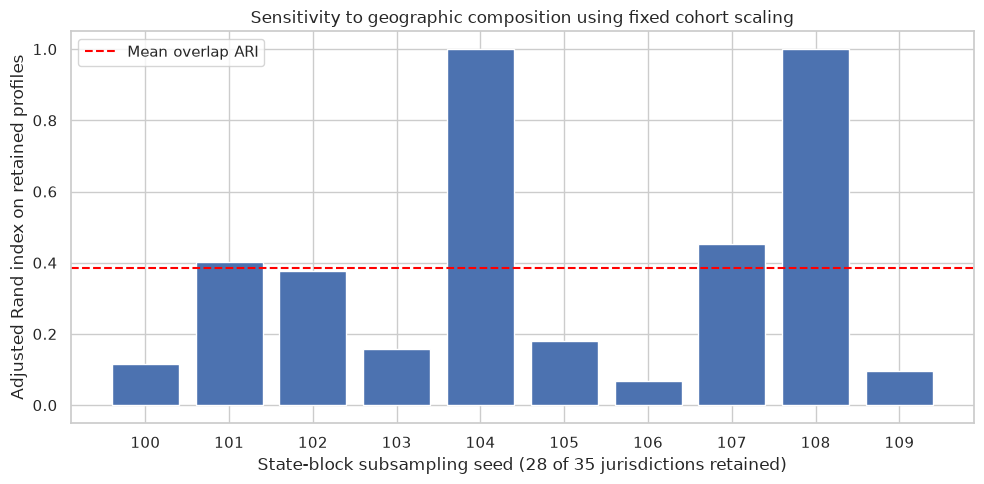

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(stability.seed.astype(str), stability.ari_on_retained_profiles)
ax.axhline(stability.ari_on_retained_profiles.mean(), color="red", linestyle="--", label="Mean overlap ARI")
ax.set_ylim(min(-.05, stability.ari_on_retained_profiles.min() - .05), 1.05)
ax.set_xlabel("State-block subsampling seed (28 of 35 jurisdictions retained)")
ax.set_ylabel("Adjusted Rand index on retained profiles")
ax.set_title("Sensitivity to geographic composition using fixed cohort scaling")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "state_block_stability.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** Initialization mean pairwise ARI is 0.330. Ten state-block refits have mean overlap ARI 0.385 (range 0.069–1.000). Each refit retains complete state-year blocks from 28 jurisdictions and uses BUILD plus two random starts. Fixed full-cohort scaling makes this descriptive sensitivity, not held-out validation. At fixed k=2, distance sensitivity ARI is 0.867; distance-specific preferred k still differs.

## Verification and conclusion

Independent complete reassignment verifies every one-medoid swap of the final solution and finds no improving swap above tolerance. The six-point algorithm fixture is checked against every possible two-medoid choice. Tests cover ties, invalid inputs, monotonic objectives, actual representative identities, saved assignments and the declared selection rule. The source follows PAM references; R is not installed, so no executed R comparison is claimed.

The low silhouette and sensitivity argue against presenting these clusters as stable natural classes. We retain them as an exploratory description of this historical cohort. We report no classification accuracy, causal effect or predictive performance. No Naive Bayes, MAFIA or PySpark algorithm is executed in this phase.

In [10]:
from src.preprocessing.cleaning import sha256
for source in summary["upstream_transformed_hashes"]:
    path = ROOT / "data/processed/transformed" / source["file"]
    assert sha256(path) == source["sha256"]
assert summary["converged"] and summary["exact_swap_validation"]
assert summary["best_remaining_swap_improvement"] <= summary["tol"]
assert len(assignments) == len(raw)
assert len(medoids) == summary["selected_k"]
print("Verified unchanged prepared inputs, real medoids, complete assignments and one-swap local optimality.")

Verified unchanged prepared inputs, real medoids, complete assignments and one-swap local optimality.


## References

- [Feature construction and transformation methodology](../report/data_transformation.md).
- [PAM reference](https://stat.ethz.ch/R-manual/R-devel/library/cluster/html/pam.html) and [Schubert–Rousseeuw paper](https://wis.kuleuven.be/statdatascience/robust/papers/publications-2021/schubertrousseeuw-fastpam-infsystems-2021.pdf).
- scikit-learn [silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) and [adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).